# Vision Transformer (ViT) — From Pixels to Prediction

This notebook walks through how a Vision Transformer classifies an image, one step at a time.

We use two images (a cat and a dog) and trace every tensor through the full pipeline:

```
Raw Image
  -> Preprocessing
  -> Patch Splitting
  -> Patch Embedding
  -> CLS Token
  -> Positional Embeddings
  -> Transformer Encoder (Self-Attention + FFN)
  -> MLP Classification Head
  -> Softmax -> Probabilities
```

**Prerequisites:** `pip install torch torchvision matplotlib`

---
## 1. Imports and Configuration

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import math

torch.manual_seed(0)
np.random.seed(0)

# ViT-Base configuration (same as the original paper)
IMG_SIZE   = 224
PATCH_SIZE = 16
CHANNELS   = 3
D_MODEL    = 768
N_HEADS    = 12
N_LAYERS   = 6       # original uses 12; we use 6 to keep it readable
D_FF       = 3072    # 4 * D_MODEL
N_CLASSES  = 2       # cat vs dog
DROPOUT    = 0.1

N_PATCHES  = (IMG_SIZE // PATCH_SIZE) ** 2   # 196
SEQ_LEN    = N_PATCHES + 1                    # 197 (196 patches + 1 CLS token)
PATCH_DIM  = CHANNELS * PATCH_SIZE ** 2       # 768 raw values per patch

print("Configuration")
print("-" * 40)
print(f"Image size      : {IMG_SIZE} x {IMG_SIZE} x {CHANNELS}")
print(f"Patch size      : {PATCH_SIZE} x {PATCH_SIZE}")
print(f"Number of patches: {N_PATCHES}  (= {IMG_SIZE//PATCH_SIZE} x {IMG_SIZE//PATCH_SIZE} grid)")
print(f"Values per patch : {PATCH_DIM}  (= {CHANNELS} x {PATCH_SIZE}^2)")
print(f"d_model          : {D_MODEL}")
print(f"Attention heads  : {N_HEADS}  (d_head = {D_MODEL // N_HEADS})")
print(f"Encoder layers   : {N_LAYERS}")
print(f"Sequence length  : {SEQ_LEN}  (197 = 196 patches + 1 CLS)")
print(f"Classes          : {N_CLASSES}  (cat, dog)")

Configuration
----------------------------------------
Image size      : 224 x 224 x 3
Patch size      : 16 x 16
Number of patches: 196  (= 14 x 14 grid)
Values per patch : 768  (= 3 x 16^2)
d_model          : 768
Attention heads  : 12  (d_head = 64)
Encoder layers   : 6
Sequence length  : 197  (197 = 196 patches + 1 CLS)
Classes          : 2  (cat, dog)


---
## 2. Load two Images (Cat and Dog)



In [3]:
from PIL import Image

cat_img = torch.tensor(np.array(Image.open("cat.png").convert("RGB").resize((224, 224))) / 255.0, dtype=torch.float32).permute(2, 0, 1)
dog_img = torch.tensor(np.array(Image.open("dog.png").convert("RGB").resize((224, 224))) / 255.0, dtype=torch.float32).permute(2, 0, 1)

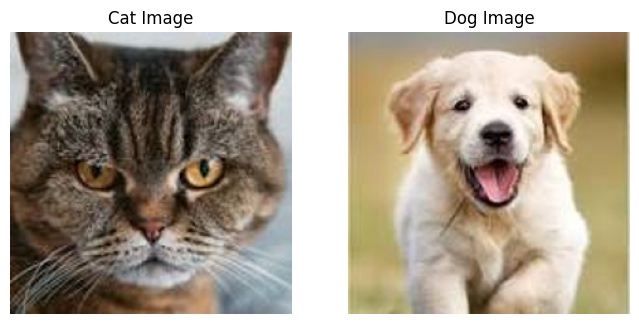

In [4]:
# Viewing the images
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(cat_img.permute(1, 2, 0))
plt.title("Cat Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(dog_img.permute(1, 2, 0))
plt.title("Dog Image")
plt.axis("off")
plt.show()

In [5]:
# get the size of the images
print(f"Cat image size: {cat_img.shape}")  # (3, 224
print(f"Dog image size: {dog_img.shape}")  # (3, 224, 224)

Cat image size: torch.Size([3, 224, 224])
Dog image size: torch.Size([3, 224, 224])


---
## 3. Preprocessing — Normalize the Pixel Values

Neural networks train better when inputs have zero mean and unit variance.
We subtract the ImageNet channel means and divide by the standard deviations.

This is the standard normalization used when ViT is pretrained on ImageNet.

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def normalize(img):
    return (img - MEAN) / STD

cat_norm = normalize(cat_img)
dog_norm = normalize(dog_img)

# Stack into a batch: shape (2, 3, 224, 224)
batch = torch.stack([cat_norm, dog_norm])

print("After normalization:")
print(f"  Batch shape   : {batch.shape}  (batch=2, C=3, H=224, W=224)")
print(f"  Value range   : [{batch.min():.3f}, {batch.max():.3f}]")
print(f"  Channel means : R={batch[:, 0].mean():.3f}  G={batch[:, 1].mean():.3f}  B={batch[:, 2].mean():.3f}")
print(f"  Channel stds  : R={batch[:, 0].std():.3f}   G={batch[:, 1].std():.3f}   B={batch[:, 2].std():.3f}")

After normalization:
  Batch shape   : torch.Size([2, 3, 224, 224])  (batch=2, C=3, H=224, W=224)
  Value range   : [-2.118, 2.640]
  Channel means : R=0.400  G=0.289  B=0.161
  Channel stds  : R=1.033   G=1.068   B=1.068


---
## 4. Patch Splitting

The core idea of ViT: treat image regions as tokens.

A 224x224 image is cut into a 14x14 grid of non-overlapping 16x16 patches.
That gives **196 patches**. Each patch is then flattened into a vector of
`16 * 16 * 3 = 768` values.





Patch splitting:
  Input  shape: torch.Size([2, 3, 224, 224])
  Output shape: torch.Size([2, 196, 768])  (batch, N_patches, patch_dim)
  N_patches = 196 = 14 x 14 grid
  patch_dim = 768 = 16*16*3 raw pixel values per patch

Sample patch values (cat, patch 0 = top-left, first 8 values):
  [ 1.632  1.581  1.41   1.119  0.297 -0.594 -1.056 -1.142]
Sample patch values (cat, patch 98 = center, first 8 values):
  [-0.32  -0.405 -0.525 -0.628 -0.662 -0.662 -0.679 -0.662]


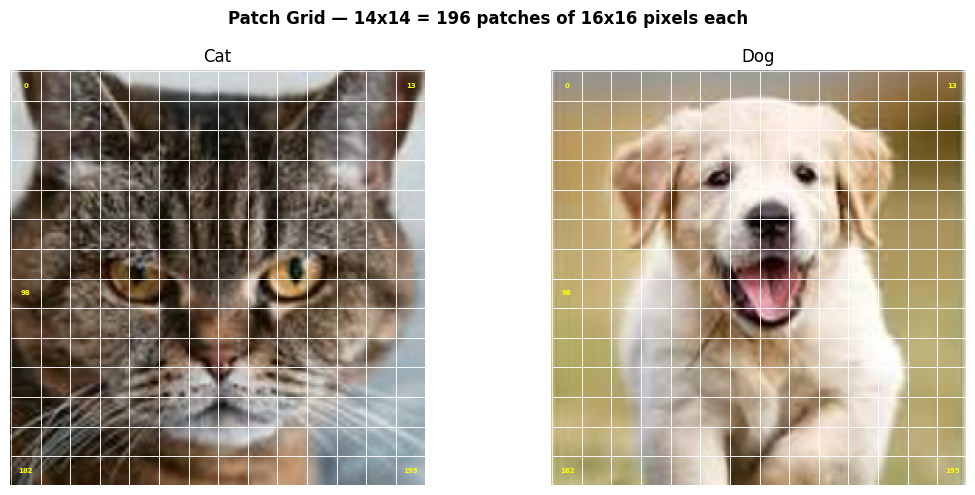

In [7]:
def split_into_patches(x, patch_size):
    """
    Split a batch of images into flattened patch vectors.

    Input : (B, C, H, W)
    Output: (B, N_patches, patch_size^2 * C)
    """
    B, C, H, W = x.shape
    P = patch_size
    n_h = H // P
    n_w = W // P

    # Reshape: split H and W into (n_h, P) and (n_w, P)
    x = x.view(B, C, n_h, P, n_w, P)
    # Reorder so patches are on the first sequence dimension
    x = x.permute(0, 2, 4, 1, 3, 5).contiguous()   # (B, n_h, n_w, C, P, P)
    # Flatten the spatial patch and channel dims
    x = x.view(B, n_h * n_w, C * P * P)             # (B, N_patches, patch_dim)
    return x

    # The image is now a sequence of 196 vectors, each 768 numbers long.


patches = split_into_patches(batch, PATCH_SIZE)

print("Patch splitting:")
print(f"  Input  shape: {batch.shape}")
print(f"  Output shape: {patches.shape}  (batch, N_patches, patch_dim)")
print(f"  N_patches = {N_PATCHES} = 14 x 14 grid")
print(f"  patch_dim = {PATCH_DIM} = 16*16*3 raw pixel values per patch")
print()
print("Sample patch values (cat, patch 0 = top-left, first 8 values):")
print(f"  {patches[0, 0, :8].numpy().round(3)}")
print("Sample patch values (cat, patch 98 = center, first 8 values):")
print(f"  {patches[0, 98, :8].numpy().round(3)}")

# Visualize the patch grid on the cat image
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("Patch Grid — 14x14 = 196 patches of 16x16 pixels each",
             fontsize=12, fontweight='bold')

images_display = [cat_img, dog_img]
labels_display = ["Cat", "Dog"]
n_grid = IMG_SIZE // PATCH_SIZE   # 14

for ax, img_t, lbl in zip(axes, images_display, labels_display):
    ax.imshow(img_t.permute(1, 2, 0).numpy())
    for row in range(n_grid):
        for col in range(n_grid):
            rect = mpatches.Rectangle(
                (col * PATCH_SIZE, row * PATCH_SIZE), PATCH_SIZE, PATCH_SIZE,
                linewidth=0.5, edgecolor='white', facecolor='none'
            )
            ax.add_patch(rect)
    # Label a handful of patches for reference
    for idx in [0, 13, 98, 182, 195]:
        r, c = divmod(idx, n_grid)
        ax.text(c * PATCH_SIZE + PATCH_SIZE // 2,
                r * PATCH_SIZE + PATCH_SIZE // 2,
                str(idx), color='yellow', fontsize=5,
                ha='center', va='center', fontweight='bold')
    ax.set_title(f"{lbl}")
    ax.axis('off')

plt.tight_layout()
plt.show()

---
## 5. Patch Embedding — Project Each Patch to d_model

Each patch is currently a vector of 768 raw pixel values.
A learned linear layer projects this to a 768-dimensional embedding
(in ViT-Base, input and output dim happen to match; in general they can differ).

This is analogous to the word embedding table in NLP: raw tokens become dense vectors.

In [8]:
patch_embed_layer = nn.Linear(PATCH_DIM, D_MODEL, bias=False)

patch_emb = patch_embed_layer(patches)   # (2, 196, 768)

print("Patch embedding:")
print(f"  Input  shape: {patches.shape}   (B, N_patches, patch_dim={PATCH_DIM})")
print(f"  Weight shape: {patch_embed_layer.weight.shape}  (d_model, patch_dim)")
print(f"  Output shape: {patch_emb.shape}  (B, N_patches, d_model={D_MODEL})")
print()
print("Patch 0 embedding — first 8 dims (cat):")
print(f"  {patch_emb[0, 0, :8].detach().numpy().round(4)}")
print("Patch 0 embedding — first 8 dims (dog):")
print(f"  {patch_emb[1, 0, :8].detach().numpy().round(4)}")

Patch embedding:
  Input  shape: torch.Size([2, 196, 768])   (B, N_patches, patch_dim=768)
  Weight shape: torch.Size([768, 768])  (d_model, patch_dim)
  Output shape: torch.Size([2, 196, 768])  (B, N_patches, d_model=768)

Patch 0 embedding — first 8 dims (cat):
  [-0.2704  0.326  -1.3178  0.1621 -0.161  -0.7171  1.0476  1.1869]
Patch 0 embedding — first 8 dims (dog):
  [-0.2459 -0.2208  0.104  -0.3177 -0.6789 -0.1628 -0.0501  0.4731]


---
## 6. CLS Token

A single learnable token is prepended to the sequence.
It starts with no image content. Over the encoder layers, self-attention
lets it collect information from all 196 patches.
At the end, its output vector is used for classification.

In [9]:
cls_token = nn.Parameter(torch.randn(1, 1, D_MODEL) * 0.02)

B = patch_emb.size(0)
cls_expanded = cls_token.expand(B, -1, -1)           # (2, 1, 768)
tokens = torch.cat([cls_expanded, patch_emb], dim=1) # (2, 197, 768)

print("CLS token:")
print(f"  CLS token shape (before expand): {cls_token.shape}")
print(f"  CLS token expanded over batch  : {cls_expanded.shape}")
print(f"  Patch embeddings               : {patch_emb.shape}")
print(f"  After prepend CLS              : {tokens.shape}  (B, 1+196, d_model)")
print()
print("Token layout:")
print(f"  Position 0       -> CLS token (classification vector)")
print(f"  Positions 1-196  -> Patch embeddings")

CLS token:
  CLS token shape (before expand): torch.Size([1, 1, 768])
  CLS token expanded over batch  : torch.Size([2, 1, 768])
  Patch embeddings               : torch.Size([2, 196, 768])
  After prepend CLS              : torch.Size([2, 197, 768])  (B, 1+196, d_model)

Token layout:
  Position 0       -> CLS token (classification vector)
  Positions 1-196  -> Patch embeddings


---
## 7. Positional Embeddings

Self-attention has no built-in sense of order.
Without positional information, the model cannot tell patch 0 (top-left)
from patch 195 (bottom-right).

ViT adds a learned embedding vector for each of the 197 positions.
These are added directly to the token vectors (not concatenated).

In [10]:
pos_embed = nn.Parameter(torch.randn(1, SEQ_LEN, D_MODEL) * 0.02)  # (1, 197, 768)

x = tokens + pos_embed   # (2, 197, 768)

print("Positional embeddings:")
print(f"  pos_embed shape : {pos_embed.shape}  (1, SEQ_LEN=197, d_model=768)")
print(f"  Broadcasts over batch dimension")
print(f"  Input tokens    : {tokens.shape}")
print(f"  Output (x)      : {x.shape}  <- same shape, PE is added not concatenated")
print()
print("Token at position 0 before and after adding PE (cat, first 5 dims):")
print(f"  Before: {tokens[0, 0, :5].detach().numpy().round(4)}")
print(f"  After : {x[0, 0, :5].detach().numpy().round(4)}")


Positional embeddings:
  pos_embed shape : torch.Size([1, 197, 768])  (1, SEQ_LEN=197, d_model=768)
  Broadcasts over batch dimension
  Input tokens    : torch.Size([2, 197, 768])
  Output (x)      : torch.Size([2, 197, 768])  <- same shape, PE is added not concatenated

Token at position 0 before and after adding PE (cat, first 5 dims):
  Before: [-0.0426 -0.0136 -0.0054 -0.0359  0.0087]
  After : [-0.0332 -0.0125 -0.0262 -0.0331  0.0163]


---
## 8. Scaled Dot-Product Attention

This is the core mechanism. For each token, it computes how much attention to pay to every other token.
```
Attention(Q, K, V) = softmax( Q @ K^T / sqrt(d_k) ) @ V
```

Each token x of shape (768,) is projected into three smaller vectors using three independent learned weight matrices W_Q, W_K, W_V. These matrices are randomly initialised and updated during training. They are not the same matrix — each learns to extract a different aspect of each token.

The output dimension 64 comes from D_MODEL / N_HEADS = 768 / 12 = 64. Each head works in its own 64-dimensional subspace.
```
# Single token projection — inner dim 768 cancels
x (1, 768) @ W_Q (768, 64) = q (1, 64)   <- query : what am I looking for?
x (1, 768) @ W_K (768, 64) = k (1, 64)   <- key   : what do I contain?
x (1, 768) @ W_V (768, 64) = v (1, 64)   <- value : what do I share?

# Full sequence — all 197 tokens at once
X (197, 768) @ W_Q (768, 64) = Q (197, 64)
X (197, 768) @ W_K (768, 64) = K (197, 64)
X (197, 768) @ W_V (768, 64) = V (197, 64)

# Score every token pair — K^T flips K from (197, 64) to (64, 197)
scores  = Q @ K^T   : (197, 64) @ (64, 197) = (197, 197)
# cell (i, j) = how much token i attends to token j

# Scale to stabilise softmax
scaled  = scores / sqrt(64) = scores / 8    : (197, 197)

# Convert to probabilities — each row sums to 1.0
weights = softmax(scaled)                   : (197, 197)

# Weighted average of values
output  = weights @ V : (197, 197) @ (197, 64) = (197, 64)
# output[i] blends all 197 value vectors weighted by attention

# This runs 12 times in parallel, one per head
# Each head produces (197, 64)
# Concatenate all heads -> (197, 768)
```

In [11]:
def scaled_dot_product_attention(Q, K, V):
    """
    Q, K, V: (B, heads, T, d_k)
    Returns: output (B, heads, T, d_k), weights (B, heads, T, T)
    """
    d_k    = Q.size(-1)
    scores  = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)  # (B, h, T, T)
    weights = F.softmax(scores, dim=-1)                               # (B, h, T, T)
    output  = torch.matmul(weights, V)                                # (B, h, T, d_k)
    return output, weights


# Demonstrate with a small example
B_demo, T_demo, d_k_demo = 1, 5, 8
Q_demo = torch.randn(B_demo, 1, T_demo, d_k_demo)
K_demo = torch.randn(B_demo, 1, T_demo, d_k_demo)
V_demo = torch.randn(B_demo, 1, T_demo, d_k_demo)

out_demo, w_demo = scaled_dot_product_attention(Q_demo, K_demo, V_demo)

print("Scaled dot-product attention (small demo):")
print(f"  Q shape           : {Q_demo.shape}")
print(f"  K shape           : {K_demo.shape}")
print(f"  V shape           : {V_demo.shape}")
print(f"  Scores: Q @ K^T   : ({B_demo}, 1, {T_demo}, {T_demo})")
print(f"  Scale  1/sqrt(d_k): 1/sqrt({d_k_demo}) = {1/math.sqrt(d_k_demo):.4f}")
print(f"  Weights (softmax) : {w_demo.shape}")
print(f"  Each row sums to  : {w_demo[0, 0, 0].sum().item():.4f}")
print(f"  Output shape      : {out_demo.shape}")
print()
print("Attention weight matrix (token 0 attends to all 5 tokens):")
print(f"  {w_demo[0, 0, 0].detach().numpy().round(4)}")

Scaled dot-product attention (small demo):
  Q shape           : torch.Size([1, 1, 5, 8])
  K shape           : torch.Size([1, 1, 5, 8])
  V shape           : torch.Size([1, 1, 5, 8])
  Scores: Q @ K^T   : (1, 1, 5, 5)
  Scale  1/sqrt(d_k): 1/sqrt(8) = 0.3536
  Weights (softmax) : torch.Size([1, 1, 5, 5])
  Each row sums to  : 1.0000
  Output shape      : torch.Size([1, 1, 5, 8])

Attention weight matrix (token 0 attends to all 5 tokens):
  [0.2311 0.3356 0.2209 0.0983 0.1141]


---
## 9. Multi-Head Self-Attention

Instead of one attention computation, we run h=12 in parallel (the "heads").
Each head works in a lower-dimensional space (d_k = 768/12 = 64),
and can specialize in different spatial or semantic relationships.
The outputs are concatenated and projected back to d_model.

Multi-Head Self-Attention:
  Input  shape: torch.Size([2, 197, 768])  (B=2, T=197, D=768)
  n_heads = 12, d_k = 64 per head
  Output shape: torch.Size([2, 197, 768])  (same as input)
  Weights shape: torch.Size([2, 12, 197, 197])  (B, heads, T, T)

How much does CLS (position 0) attend to each patch?
Head 0 — CLS attention over all 196 patches (first 10 shown):
  [0.0051 0.0051 0.0051 0.0051 0.0051 0.0051 0.0052 0.0052 0.0052 0.0052]
  Sum of all patch weights: 0.9949


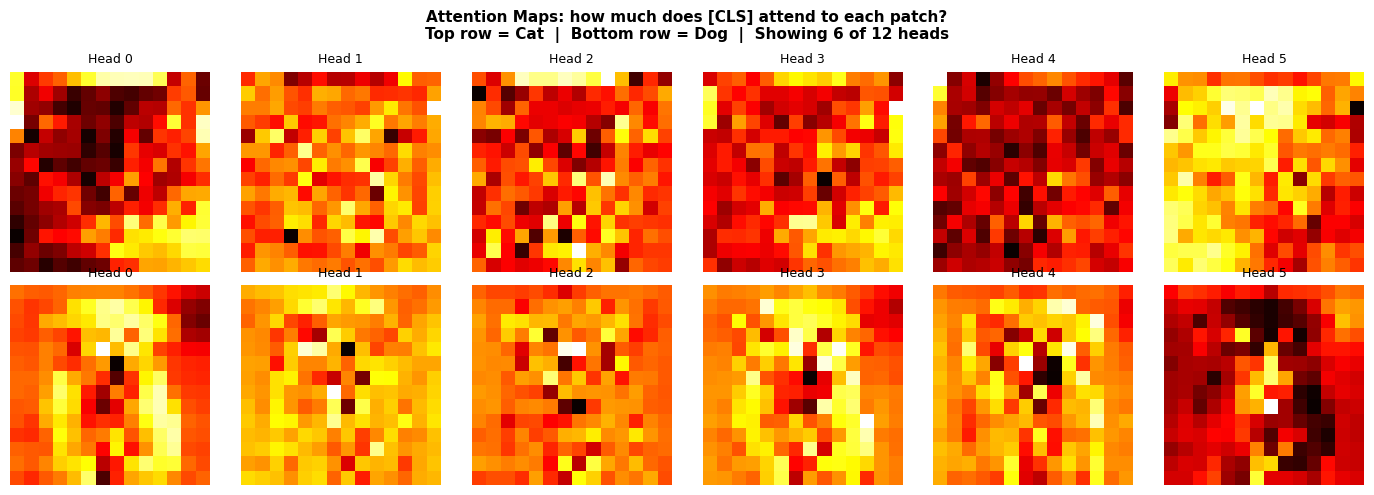

In [12]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.n_heads = n_heads
        self.d_k     = d_model // n_heads

        # Single fused projection for Q, K and V
        self.qkv_proj = nn.Linear(d_model, 3 * d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.dropout  = nn.Dropout(dropout)

    def forward(self, x):
        B, T, D = x.shape
        h, dk   = self.n_heads, self.d_k

        # 1. Project to Q, K, V
        qkv = self.qkv_proj(x)              # (B, T, 3*D)
        Q, K, V = qkv.chunk(3, dim=-1)      # each (B, T, D)

        # 2. Split into heads
        def to_heads(t):
            return t.view(B, T, h, dk).transpose(1, 2)  # (B, h, T, dk)
        Q, K, V = to_heads(Q), to_heads(K), to_heads(V)

        # 3. Attention
        context, weights = scaled_dot_product_attention(Q, K, V)  # (B, h, T, dk)
        context = self.dropout(context)

        # 4. Recombine heads
        context = context.transpose(1, 2).contiguous().view(B, T, D)  # (B, T, D)

        # 5. Output projection
        out = self.out_proj(context)   # (B, T, D)
        return out, weights.detach()


mhsa = MultiHeadSelfAttention(D_MODEL, N_HEADS, DROPOUT)

attn_out, attn_weights = mhsa(x)

print("Multi-Head Self-Attention:")
print(f"  Input  shape: {x.shape}  (B=2, T=197, D=768)")
print(f"  n_heads = {N_HEADS}, d_k = {D_MODEL // N_HEADS} per head")
print(f"  Output shape: {attn_out.shape}  (same as input)")
print(f"  Weights shape: {attn_weights.shape}  (B, heads, T, T)")
print()
print("How much does CLS (position 0) attend to each patch?")
print("Head 0 — CLS attention over all 196 patches (first 10 shown):")
cls_attn_head0 = attn_weights[0, 0, 0, 1:]
print(f"  {cls_attn_head0[:10].numpy().round(4)}")
print(f"  Sum of all patch weights: {cls_attn_head0.sum().item():.4f}")

# Show 6 heads only (one row per image, one column per head)
HEADS_TO_SHOW = 6
n_grid = IMG_SIZE // PATCH_SIZE  # 14

fig, axes = plt.subplots(2, HEADS_TO_SHOW, figsize=(14, 5))
fig.suptitle(
    f"Attention Maps: how much does [CLS] attend to each patch?\n"
    f"Top row = Cat  |  Bottom row = Dog  |  Showing {HEADS_TO_SHOW} of {N_HEADS} heads",
    fontsize=11, fontweight='bold'
)
for img_idx in range(2):
    for col, head in enumerate(range(HEADS_TO_SHOW)):
        attn_map = attn_weights[img_idx, head, 0, 1:].numpy().reshape(n_grid, n_grid)
        axes[img_idx, col].imshow(attn_map, cmap='hot')
        axes[img_idx, col].set_title(f"Head {head}", fontsize=9)
        axes[img_idx, col].axis('off')

plt.tight_layout()
plt.show()

---
## 10. Feed-Forward Network (FFN)

After attention mixes information across tokens, the FFN processes
each token independently with two linear layers and a GELU activation.

It expands the representation to 4x the size, then contracts it back:
`d_model (768) -> d_ff (3072) -> d_model (768)`

In [13]:
class FFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1     = nn.Linear(d_model, d_ff)
        self.fc2     = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)          # (B, T, d_ff)
        x = F.gelu(x)            # non-linearity
        x = self.dropout(x)
        x = self.fc2(x)          # (B, T, d_model)
        return x


ffn = FFN(D_MODEL, D_FF, DROPOUT)
ffn_out = ffn(attn_out)

print("Feed-Forward Network:")
print(f"  Input  : {attn_out.shape}  (B, T, d_model={D_MODEL})")
print(f"  fc1    : d_model={D_MODEL} -> d_ff={D_FF}")
print(f"  GELU   : non-linearity (smoother than ReLU)")
print(f"  fc2    : d_ff={D_FF} -> d_model={D_MODEL}")
print(f"  Output : {ffn_out.shape}  (same shape as input)")
print()
print("The FFN is applied to each of the 197 tokens independently.")
print("It adds capacity for the model to transform each token's representation.")

Feed-Forward Network:
  Input  : torch.Size([2, 197, 768])  (B, T, d_model=768)
  fc1    : d_model=768 -> d_ff=3072
  GELU   : non-linearity (smoother than ReLU)
  fc2    : d_ff=3072 -> d_model=768
  Output : torch.Size([2, 197, 768])  (same shape as input)

The FFN is applied to each of the 197 tokens independently.
It adds capacity for the model to transform each token's representation.


---
## 11. Full Encoder Block and Encoder Stack

One encoder block combines MHSA and FFN with:
- **Layer Normalization** before each sub-layer (Pre-LN variant)
- **Residual connections** after each sub-layer

Residual connections let gradients flow directly through the network during training,
making it possible to train deep models without vanishing gradients.

We stack N_LAYERS of these blocks.

In [70]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn  = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn   = FFN(d_model, d_ff, dropout)

    def forward(self, x):
        # Sub-layer 1: self-attention with residual
        attn_out, weights = self.attn(self.norm1(x))
        x = x + attn_out

        # Sub-layer 2: FFN with residual
        x = x + self.ffn(self.norm2(x))
        return x, weights


class TransformerEncoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.blocks = nn.ModuleList(
            [EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)]
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        all_weights = []
        for block in self.blocks:
            x, w = block(x)
            all_weights.append(w)
        x = self.norm(x)
        return x, all_weights


encoder = TransformerEncoder(N_LAYERS, D_MODEL, N_HEADS, D_FF, DROPOUT)

# x is our token sequence with positional embeddings added
encoder_out, layer_weights = encoder(x)

print("Transformer Encoder:")
print(f"  Input  shape: {x.shape}")
print(f"  Output shape: {encoder_out.shape}  (same — encoder preserves shape)")
print(f"  Number of blocks   : {N_LAYERS}")
print(f"  Attention maps saved: {len(layer_weights)} layers x {layer_weights[0].shape}")
print()

# Count parameters
n_params = sum(p.numel() for p in encoder.parameters())
print(f"  Encoder parameters: {n_params:,}")
print()
print("Each block:")
print("  x = x + MHSA( LayerNorm(x) )   <- self-attention + residual")
print("  x = x + FFN(  LayerNorm(x) )   <- FFN + residual")

Transformer Encoder:
  Input  shape: torch.Size([2, 197, 768])
  Output shape: torch.Size([2, 197, 768])  (same — encoder preserves shape)
  Number of blocks   : 6
  Attention maps saved: 6 layers x torch.Size([2, 12, 197, 197])

  Encoder parameters: 42,510,336

Each block:
  x = x + MHSA( LayerNorm(x) )   <- self-attention + residual
  x = x + FFN(  LayerNorm(x) )   <- FFN + residual


---
## 12. Extract the CLS Token Output

After N_LAYERS of self-attention, every token has been updated by attending
to every other token, across all layers.

We take only position 0 — the CLS token — as the image representation.
This single 768-dim vector is passed to the classification head.

CLS token extraction:
  Encoder output     : torch.Size([2, 197, 768])
  encoder_out[:, 0, :] selects position 0 from all images
  CLS representation : torch.Size([2, 768])  (B, d_model)

Cat CLS vector — first 8 dimensions:
  [ 0.2011  0.0672 -0.172  -0.8955 -1.0566  1.5107 -1.3328 -0.2089]
Dog CLS vector — first 8 dimensions:
  [-0.6398  0.481   0.72    0.7276  1.23    2.46    0.0737 -0.36  ]

Cosine similarity between cat and dog CLS vectors: 0.3148
(After training, different classes would have lower similarity)


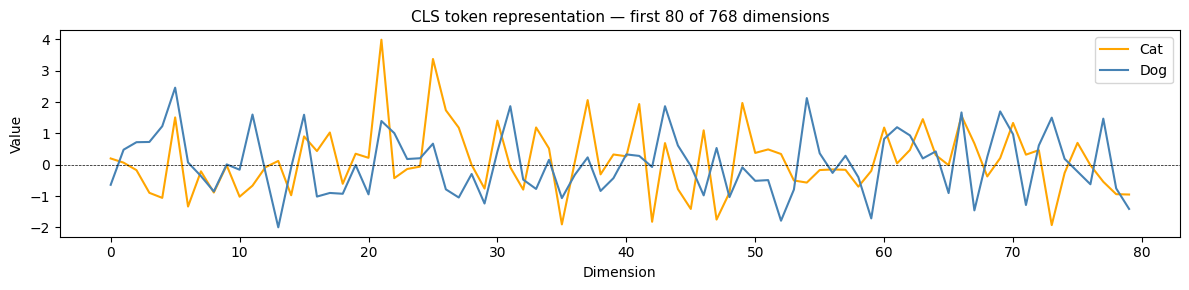

In [71]:
cls_repr = encoder_out[:, 0, :]   # (2, 768)

print("CLS token extraction:")
print(f"  Encoder output     : {encoder_out.shape}")
print(f"  encoder_out[:, 0, :] selects position 0 from all images")
print(f"  CLS representation : {cls_repr.shape}  (B, d_model)")
print()
print("Cat CLS vector — first 8 dimensions:")
print(f"  {cls_repr[0, :8].detach().numpy().round(4)}")
print("Dog CLS vector — first 8 dimensions:")
print(f"  {cls_repr[1, :8].detach().numpy().round(4)}")

cos_sim = F.cosine_similarity(cls_repr[0:1], cls_repr[1:2]).item()
print()
print(f"Cosine similarity between cat and dog CLS vectors: {cos_sim:.4f}")
print("(After training, different classes would have lower similarity)")

# Plot the CLS vectors side by side
fig, ax = plt.subplots(figsize=(12, 3))
dims = 80
ax.plot(cls_repr[0, :dims].detach().numpy(), label='Cat', color='orange', linewidth=1.5)
ax.plot(cls_repr[1, :dims].detach().numpy(), label='Dog', color='steelblue', linewidth=1.5)
ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.set_title(f"CLS token representation — first {dims} of {D_MODEL} dimensions", fontsize=11)
ax.set_xlabel("Dimension")
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()

---
## 13. MLP Classification Head

The CLS vector goes through a small MLP that outputs one logit per class.
For our cat-vs-dog task: 768 -> 768 -> 2.

In [72]:
class MLPHead(nn.Module):
    def __init__(self, d_model, n_classes, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, n_classes)
        )

    def forward(self, x):
        return self.net(x)


mlp_head = MLPHead(D_MODEL, N_CLASSES, DROPOUT)
logits   = mlp_head(cls_repr)   # (2, 2)

print("MLP Classification Head:")
print(f"  Input  (CLS repr): {cls_repr.shape}  (B, d_model={D_MODEL})")
print(f"  Output (logits)  : {logits.shape}    (B, n_classes={N_CLASSES})")
print()
print("Logits (raw scores, before softmax):")
for i, lbl in enumerate(['Cat', 'Dog']):
    print(f"  {lbl}: class 0 = {logits[i, 0].item():.4f},  class 1 = {logits[i, 1].item():.4f}")
print()
print("Logits are unbounded real numbers — we apply softmax to get probabilities.")

MLP Classification Head:
  Input  (CLS repr): torch.Size([2, 768])  (B, d_model=768)
  Output (logits)  : torch.Size([2, 2])    (B, n_classes=2)

Logits (raw scores, before softmax):
  Cat: class 0 = 0.2653,  class 1 = 0.2271
  Dog: class 0 = 0.2888,  class 1 = -0.0013

Logits are unbounded real numbers — we apply softmax to get probabilities.


---
## 14. Softmax — Logits to Probabilities

Softmax converts raw logits into a probability distribution over classes:

```
P(class_i) = exp(z_i) / sum_j( exp(z_j) )
```

The result is always positive and sums to 1, so it can be interpreted as a probability.
The class with the highest probability is the prediction.

Softmax probabilities:
  Shape: torch.Size([2, 2])
  Probabilities sum to: [1.0, 1.0]  (should be 1.0 each)

  Image: Cat
    P(Cat) = 0.5095  (51.0%)
    P(Dog) = 0.4905  (49.0%)
    Prediction: Cat

  Image: Dog
    P(Cat) = 0.5720  (57.2%)
    P(Dog) = 0.4280  (42.8%)
    Prediction: Cat

Note: these predictions come from a randomly initialised model.
After training on labeled images, the probabilities would reflect
the actual content of the image.


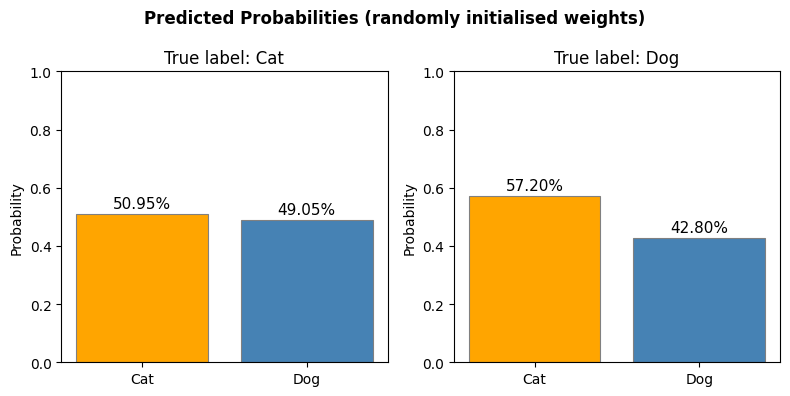

In [73]:
probs      = F.softmax(logits, dim=-1)   # (2, 2)
pred_class = logits.argmax(dim=-1)       # (2,)
class_names = ['Cat', 'Dog']

print("Softmax probabilities:")
print(f"  Shape: {probs.shape}")
print(f"  Probabilities sum to: {probs.sum(dim=-1).tolist()}  (should be 1.0 each)")
print()

for i, true_label in enumerate(class_names):
    p_cat = probs[i, 0].item()
    p_dog = probs[i, 1].item()
    pred  = class_names[pred_class[i].item()]
    print(f"  Image: {true_label}")
    print(f"    P(Cat) = {p_cat:.4f}  ({p_cat*100:.1f}%)")
    print(f"    P(Dog) = {p_dog:.4f}  ({p_dog*100:.1f}%)")
    print(f"    Prediction: {pred}")
    print()

print("Note: these predictions come from a randomly initialised model.")
print("After training on labeled images, the probabilities would reflect")
print("the actual content of the image.")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
fig.suptitle("Predicted Probabilities (randomly initialised weights)",
             fontsize=12, fontweight='bold')
colors = ['orange', 'steelblue']
for i, (ax, true_lbl) in enumerate(zip(axes, class_names)):
    vals = probs[i].detach().numpy()
    bars = ax.bar(class_names, vals, color=colors, edgecolor='gray', linewidth=0.8)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("Probability")
    ax.set_title(f"True label: {true_lbl}")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02,
                f"{v:.2%}", ha='center', fontsize=11)
plt.tight_layout()
plt.show()

---
## 15. Complete ViT Model

We now assemble all the components into a single model class
and run a clean forward pass to confirm everything works together.

In [74]:
class VisionTransformer(nn.Module):
    def __init__(self, img_size, patch_size, channels, n_classes,
                 d_model, n_heads, n_layers, d_ff, dropout=0.1):
        super().__init__()
        n_patches  = (img_size // patch_size) ** 2
        patch_dim  = channels * patch_size ** 2
        seq_len    = n_patches + 1

        # Patch embedding
        self.patch_embed = nn.Linear(patch_dim, d_model, bias=False)
        self.patch_size  = patch_size

        # CLS token and positional embeddings
        self.cls_token   = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_embed   = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        self.dropout     = nn.Dropout(dropout)

        # Transformer encoder
        self.encoder     = TransformerEncoder(n_layers, d_model, n_heads, d_ff, dropout)

        # Classification head
        self.head        = MLPHead(d_model, n_classes, dropout)

    def forward(self, x):
        B, C, H, W = x.shape
        P          = self.patch_size
        n_h, n_w   = H // P, W // P

        # 1. Split into patches and flatten
        x = x.view(B, C, n_h, P, n_w, P)
        x = x.permute(0, 2, 4, 1, 3, 5).contiguous()
        x = x.view(B, n_h * n_w, C * P * P)   # (B, N, patch_dim)

        # 2. Patch embedding
        x = self.patch_embed(x)                # (B, N, d_model)

        # 3. Prepend CLS token
        cls = self.cls_token.expand(B, -1, -1)
        x   = torch.cat([cls, x], dim=1)       # (B, N+1, d_model)

        # 4. Add positional embeddings
        x   = self.dropout(x + self.pos_embed) # (B, N+1, d_model)

        # 5. Transformer encoder
        x, _ = self.encoder(x)                 # (B, N+1, d_model)

        # 6. Extract CLS and classify
        cls_out = x[:, 0, :]                   # (B, d_model)
        logits  = self.head(cls_out)            # (B, n_classes)
        return logits


vit = VisionTransformer(
    img_size=IMG_SIZE, patch_size=PATCH_SIZE, channels=CHANNELS,
    n_classes=N_CLASSES, d_model=D_MODEL, n_heads=N_HEADS,
    n_layers=N_LAYERS, d_ff=D_FF, dropout=DROPOUT
)

vit.eval()
with torch.no_grad():
    final_logits = vit(batch)
    final_probs  = F.softmax(final_logits, dim=-1)

total_params = sum(p.numel() for p in vit.parameters())

print("Full VisionTransformer — forward pass:")
print(f"  Input  shape : {batch.shape}")
print(f"  Output shape : {final_logits.shape}  (B, n_classes)")
print(f"  Total params : {total_params:,}")
print()
print("Final predictions:")
for i, lbl in enumerate(class_names):
    p = final_probs[i].detach().numpy()
    pred = class_names[final_logits[i].argmax().item()]
    print(f"  {lbl}: P(Cat)={p[0]:.3f}  P(Dog)={p[1]:.3f}  -> Predicted: {pred}")

Full VisionTransformer — forward pass:
  Input  shape : torch.Size([2, 3, 224, 224])
  Output shape : torch.Size([2, 2])  (B, n_classes)
  Total params : 43,845,890

Final predictions:
  Cat: P(Cat)=0.502  P(Dog)=0.498  -> Predicted: Cat
  Dog: P(Cat)=0.557  P(Dog)=0.443  -> Predicted: Cat


---
## 16. Pipeline Summary

A visual recap of every shape transformation in the forward pass.

ViT Forward Pass — Shape at Each Stage

  Input image batch                   (2, 3, 224, 224)
  Normalize                           (2, 3, 224, 224)   <- values re-centered
  Split into patches                  (2, 196, 768)      <- 196 patches, 768 px each
  Patch embedding (linear)            (2, 196, 768)      <- projected to d_model
  Prepend CLS token                   (2, 197, 768)      <- 1 CLS + 196 patches
  Add positional embeddings           (2, 197, 768)      <- shape unchanged
  Encoder block x6                    (2, 197, 768)      <- shape unchanged
    - LayerNorm                       (2, 197, 768)
    - MHSA (Q,K,V)                    (2, 12, 197, 64)   <- per head
    - Attn weights                    (2, 12, 197, 197)  <- token x token
    - Concat heads                    (2, 197, 768)
    - LayerNorm + FFN                 (2, 197, 768)      768->3072->768
  Extract CLS (pos 0)                 (2, 768)           <- image summary
  MLP head                         

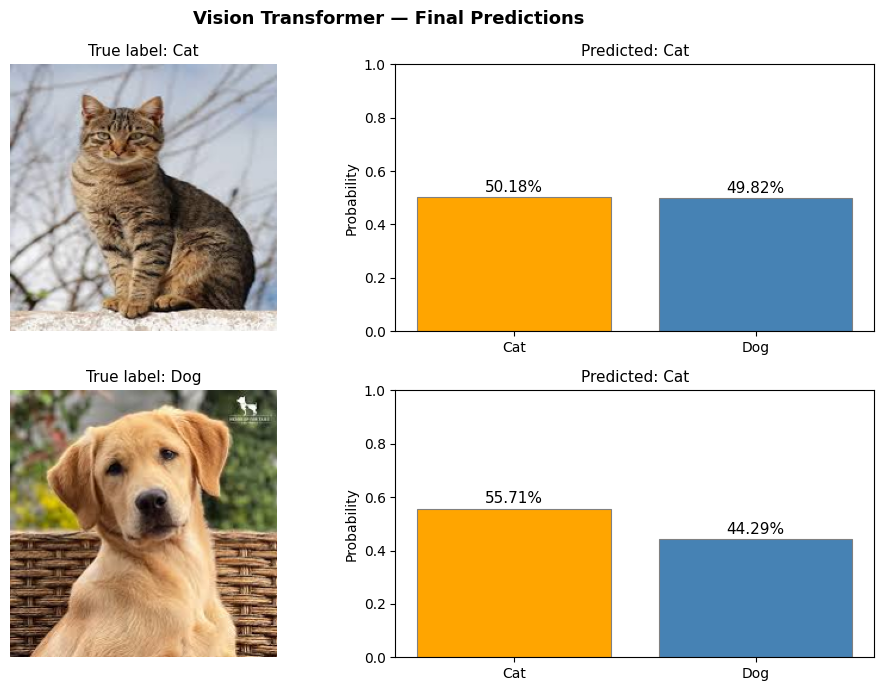


The model has random weights — it has not been trained.
Training would involve:
  1. Forward pass on labeled images
  2. Computing cross-entropy loss between predictions and true labels
  3. Backpropagation to compute gradients
  4. Optimizer step (e.g. Adam) to update all parameters
  5. Repeat over many epochs until accuracy converges


In [75]:
print("ViT Forward Pass — Shape at Each Stage")
print("=" * 55)
print()

steps = [
    ("Input image batch",          "(2, 3, 224, 224)"),
    ("Normalize",                  "(2, 3, 224, 224)   <- values re-centered"),
    ("Split into patches",         "(2, 196, 768)      <- 196 patches, 768 px each"),
    ("Patch embedding (linear)",   "(2, 196, 768)      <- projected to d_model"),
    ("Prepend CLS token",          "(2, 197, 768)      <- 1 CLS + 196 patches"),
    ("Add positional embeddings",  "(2, 197, 768)      <- shape unchanged"),
    ("Encoder block x6",           "(2, 197, 768)      <- shape unchanged"),
    ("  - LayerNorm",              "(2, 197, 768)"),
    ("  - MHSA (Q,K,V)",          "(2, 12, 197, 64)   <- per head"),
    ("  - Attn weights",           "(2, 12, 197, 197)  <- token x token"),
    ("  - Concat heads",           "(2, 197, 768)"),
    ("  - LayerNorm + FFN",        "(2, 197, 768)      768->3072->768"),
    ("Extract CLS (pos 0)",        "(2, 768)           <- image summary"),
    ("MLP head",                   "(2, 2)             <- one logit per class"),
    ("Softmax",                    "(2, 2)             <- probabilities, sum=1"),
]

for name, shape in steps:
    indent = "  " if name.startswith("  ") else ""
    print(f"  {name:<35} {shape}")

print()
print("=" * 55)
print()

# Final figure: original images and their prediction bars side by side
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle("Vision Transformer — Final Predictions", fontsize=13, fontweight='bold')

for i, (img_t, true_lbl) in enumerate(zip([cat_img, dog_img], class_names)):
    p    = final_probs[i].detach().numpy()
    pred = class_names[p.argmax()]

    axes[i, 0].imshow(img_t.permute(1, 2, 0).numpy())
    axes[i, 0].set_title(f"True label: {true_lbl}", fontsize=11)
    axes[i, 0].axis('off')

    bars = axes[i, 1].bar(class_names, p, color=['orange', 'steelblue'],
                           edgecolor='gray', linewidth=0.8)
    axes[i, 1].set_ylim(0, 1.0)
    axes[i, 1].set_ylabel("Probability")
    axes[i, 1].set_title(f"Predicted: {pred}", fontsize=11)
    for bar, v in zip(bars, p):
        axes[i, 1].text(bar.get_x() + bar.get_width() / 2, v + 0.02,
                        f"{v:.2%}", ha='center', fontsize=11)

plt.tight_layout()
plt.show()

print()
print("The model has random weights — it has not been trained.")
print("Training would involve:")
print("  1. Forward pass on labeled images")
print("  2. Computing cross-entropy loss between predictions and true labels")
print("  3. Backpropagation to compute gradients")
print("  4. Optimizer step (e.g. Adam) to update all parameters")
print("  5. Repeat over many epochs until accuracy converges")

---
## Summary

**Why patches instead of pixels?** Applying self-attention to every pixel would give a sequence of 50,176 tokens — computationally infeasible. Patches reduce this to 196.

**Why a CLS token?** It provides a single position to read off the global image representation after attention, without having to pool across all 196 patch outputs.

**Why learned positional embeddings?** They are simpler than sinusoidal and perform equally well. The model learns whatever spatial encoding is most useful for the task.

**Why multiple attention heads?** Each head can specialize. One head might focus on local texture, another on long-range spatial relationships, another on object boundaries.

**Why residual connections?** They let gradients flow directly to earlier layers, making it possible to train dozens of encoder blocks without vanishing gradients.

---
## 16. Pretrained ViT — Real Predictions

Everything above used randomly initialised weights. The pipeline is correct but the model knows nothing.

Here we load PyTorch's pretrained ViT-B/16, trained on ImageNet for 300 epochs with 1.2 million images.
We run the same two images through it and compare the results side by side.

The architecture is identical to what we built. The only difference is the weights.

In [76]:
import torchvision.models as models
import torchvision.transforms as T
from torchvision.models import ViT_B_16_Weights

# Load pretrained ViT-B/16
weights   = ViT_B_16_Weights.IMAGENET1K_V1
vit_pt    = models.vit_b_16(weights=weights)
vit_pt.eval()

total_params = sum(p.numel() for p in vit_pt.parameters())
print('Pretrained ViT-B/16')
print('-' * 40)
print(f'  Parameters : {total_params:,}  (~86 million)')
print(f'  Trained on : ImageNet-1k  (1,281,167 images, 1000 classes)')
print(f'  Architecture: 12 blocks, d_model=768, 12 heads')
print(f'  Our model  : 6 blocks, same d_model and heads, random weights')

# Preprocessing the pretrained model expects
preprocess = T.Compose([
    T.ToPILImage(),
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ImageNet class names
imagenet_classes = weights.meta['categories']

# Run both images through pretrained model
batch_pt = torch.stack([preprocess(cat_img), preprocess(dog_img)])

with torch.no_grad():
    logits_pt = vit_pt(batch_pt)              # (2, 1000)
    probs_pt  = F.softmax(logits_pt, dim=-1)  # (2, 1000)

print()
print('Pretrained model output shape:', logits_pt.shape, '  (2 images, 1000 classes)')
print()

image_names = ['Cat', 'Dog']
for i, name in enumerate(image_names):
    top5_probs, top5_idx = probs_pt[i].topk(5)
    print(f'  {name} — Top 5 predictions:')
    for prob, idx in zip(top5_probs, top5_idx):
        print(f'    {imagenet_classes[idx.item()]:<35} {prob.item()*100:5.1f}%')
    print()

Pretrained ViT-B/16
----------------------------------------
  Parameters : 86,567,656  (~86 million)
  Trained on : ImageNet-1k  (1,281,167 images, 1000 classes)
  Architecture: 12 blocks, d_model=768, 12 heads
  Our model  : 6 blocks, same d_model and heads, random weights

Pretrained model output shape: torch.Size([2, 1000])   (2 images, 1000 classes)

  Cat — Top 5 predictions:
    tabby                                41.3%
    tiger cat                            27.3%
    Egyptian cat                         19.9%
    lynx                                  0.2%
    Persian cat                           0.0%

  Dog — Top 5 predictions:
    Labrador retriever                   57.0%
    golden retriever                     25.0%
    hamper                                2.3%
    Rhodesian ridgeback                   0.4%
    tennis ball                           0.3%



---
## 17. Side-by-Side Comparison: Random vs Pretrained

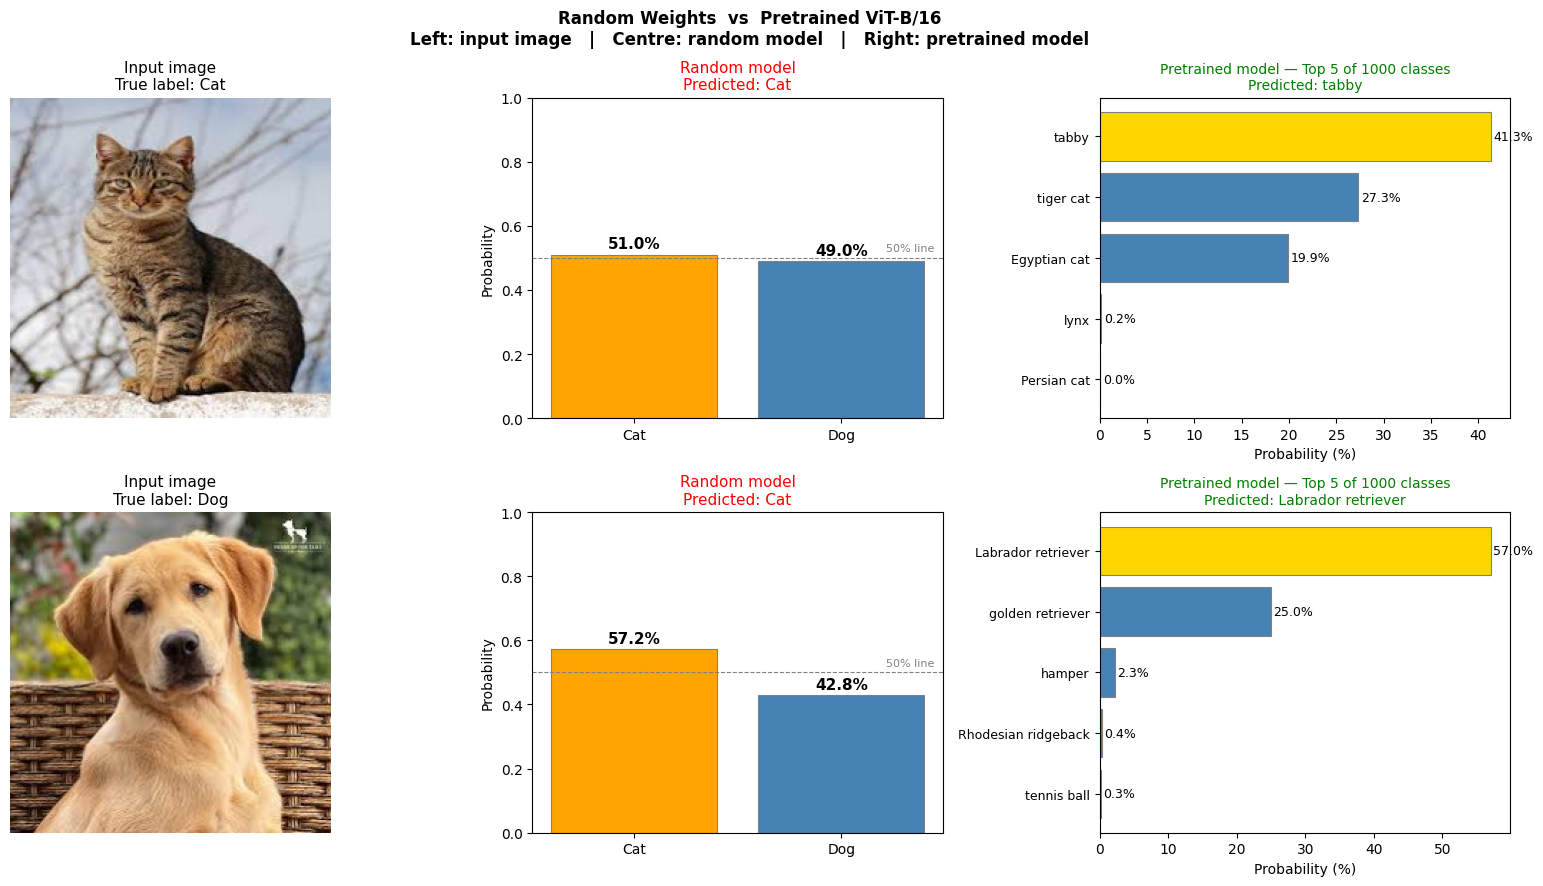

Summary
--------------------------------------------------
  True label : Cat
  Random     : Cat         confidence 51.0%  <- near random
  Pretrained : tabby                               confidence 41.3%

  True label : Dog
  Random     : Cat         confidence 57.2%  <- near random
  Pretrained : Labrador retriever                  confidence 57.0%



In [77]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle(
    'Random Weights  vs  Pretrained ViT-B/16\n'
    'Left: input image   |   Centre: random model   |   Right: pretrained model',
    fontsize=12, fontweight='bold'
)

images_display = [cat_img, dog_img]
true_labels    = ['Cat', 'Dog']
bar_colors     = ['orange', 'steelblue']

for row, (img_t, true_lbl) in enumerate(zip(images_display, true_labels)):

    # Column 0: input image
    axes[row, 0].imshow(img_t.permute(1, 2, 0).numpy())
    axes[row, 0].set_title(f'Input image\nTrue label: {true_lbl}', fontsize=11)
    axes[row, 0].axis('off')

    # Column 1: random model (2 classes)
    rand_vals = probs[row].detach().numpy()
    rand_pred = class_names[probs[row].argmax().item()]
    rand_bars = axes[row, 1].bar(
        ['Cat', 'Dog'], rand_vals,
        color=bar_colors, edgecolor='gray', linewidth=0.8
    )
    axes[row, 1].set_ylim(0, 1.0)
    axes[row, 1].set_ylabel('Probability')
    axes[row, 1].set_title(f'Random model\nPredicted: {rand_pred}', fontsize=11, color='red')
    axes[row, 1].axhline(0.5, color='gray', linewidth=0.8, linestyle='--')
    axes[row, 1].text(0.98, 0.52, '50% line', transform=axes[row, 1].transAxes,
                      ha='right', fontsize=8, color='gray')
    for bar, v in zip(rand_bars, rand_vals):
        axes[row, 1].text(
            bar.get_x() + bar.get_width() / 2, v + 0.02,
            f'{v:.1%}', ha='center', fontsize=11, fontweight='bold'
        )

    # Column 2: pretrained model (top 5 of 1000 classes)
    top5_probs, top5_idx = probs_pt[row].topk(5)
    top5_names = [imagenet_classes[i.item()] for i in top5_idx]
    top5_vals  = top5_probs.numpy()
    pt_pred    = top5_names[0]

    pt_colors = ['gold'] + ['steelblue'] * 4
    pt_bars   = axes[row, 2].barh(
        range(5), top5_vals * 100,
        color=pt_colors, edgecolor='gray', linewidth=0.8
    )
    axes[row, 2].set_yticks(range(5))
    axes[row, 2].set_yticklabels([f'{n[:28]}' for n in top5_names], fontsize=9)
    axes[row, 2].invert_yaxis()
    axes[row, 2].set_xlabel('Probability (%)')
    axes[row, 2].set_title(
        f'Pretrained model — Top 5 of 1000 classes\nPredicted: {pt_pred[:30]}',
        fontsize=10, color='green'
    )
    for bar, v in zip(pt_bars, top5_vals):
        axes[row, 2].text(
            bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{v*100:.1f}%', va='center', fontsize=9
        )

plt.tight_layout()
plt.savefig('random_vs_pretrained.png', dpi=120, bbox_inches='tight')
plt.show()

print('Summary')
print('-' * 50)
for row, true_lbl in enumerate(true_labels):
    rand_pred = class_names[probs[row].argmax().item()]
    rand_conf = probs[row].max().item()
    pt_pred   = imagenet_classes[probs_pt[row].argmax().item()]
    pt_conf   = probs_pt[row].max().item()
    print(f'  True label : {true_lbl}')
    print(f'  Random     : {rand_pred:<10}  confidence {rand_conf*100:.1f}%  <- near random')
    print(f'  Pretrained : {pt_pred:<35} confidence {pt_conf*100:.1f}%')
    print()